In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# 检查运行设备
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

# 将图像转换为 Tensor
transform = transforms.ToTensor()

# 下载训练集和测试集
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

PyTorch version: 2.11.0+cu128
Device: cuda
Training samples: 60000
Test samples: 10000


Image shape: torch.Size([1, 28, 28])
Label: 5
Pixel range: 0.0 1.0


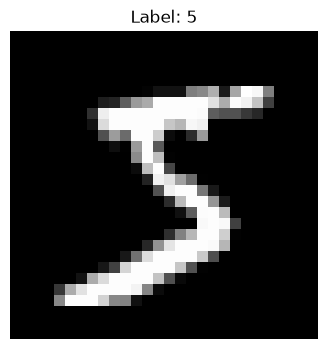

In [2]:
# 读取一张图片及其标签
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Pixel range:", image.min().item(), image.max().item())

# 显示图片
plt.figure(figsize=(4, 4))
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

In [3]:
# 创建批量数据加载器
batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

# 查看一个批次的数据
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("First 10 labels:", labels[:10].tolist())

Images shape: torch.Size([128, 1, 28, 28])
Labels shape: torch.Size([128])
First 10 labels: [7, 4, 2, 4, 8, 4, 0, 3, 2, 4]


In [4]:
from model import LeNet

# 创建 LeNet 模型并放到 GPU
model = LeNet().to(device)

# 从 DataLoader 获取一批图片
images, labels = next(iter(train_loader))

# 将图片移动到 GPU
images = images.to(device)

# 执行前向传播
with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Model device:", next(model.parameters()).device)

Input shape: torch.Size([128, 1, 28, 28])
Output shape: torch.Size([128, 10])
Model device: cuda:0


In [5]:
# 统计模型中可训练的参数
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 44426
Trainable parameters: 44426


   epoch  train_loss  train_accuracy  test_loss  test_accuracy
0      1    0.403990        0.879633   0.116882         0.9640
1      2    0.109831        0.966200   0.076224         0.9750
2      3    0.077014        0.975983   0.059296         0.9804
3      4    0.059476        0.981083   0.053610         0.9829
4      5    0.049760        0.984633   0.046620         0.9861


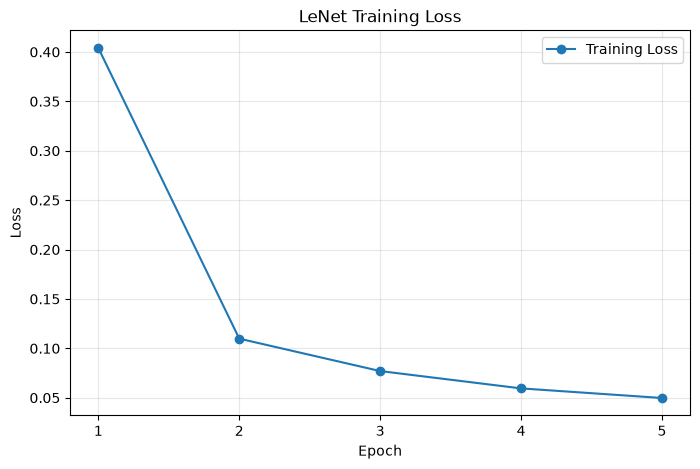

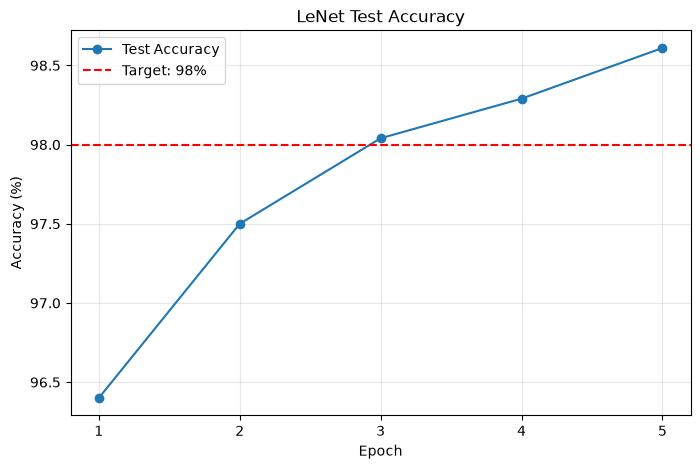

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# 读取训练指标
metrics = pd.read_csv("results/metrics.csv")

print(metrics)

# 绘制训练 Loss 曲线
plt.figure(figsize=(8, 5))

plt.plot(
    metrics["epoch"],
    metrics["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LeNet Training Loss")
plt.xticks(metrics["epoch"])
plt.grid(alpha=0.3)
plt.legend()

plt.savefig(
    "results/loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 绘制测试 Accuracy 曲线
plt.figure(figsize=(8, 5))

plt.plot(
    metrics["epoch"],
    metrics["test_accuracy"] * 100,
    marker="o",
    label="Test Accuracy"
)

plt.axhline(
    y=98,
    color="red",
    linestyle="--",
    label="Target: 98%"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("LeNet Test Accuracy")
plt.xticks(metrics["epoch"])
plt.grid(alpha=0.3)
plt.legend()

plt.savefig(
    "results/accuracy_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
from model import LeNet
import torch

# 创建模型
best_model = LeNet().to(device)

# 加载训练好的模型参数
best_model.load_state_dict(
    torch.load(
        "results/lenet_best.pth",
        map_location=device,
        weights_only=True
    )
)

# 切换为评估模式
best_model.eval()

print("Best LeNet model loaded successfully.")

Best LeNet model loaded successfully.


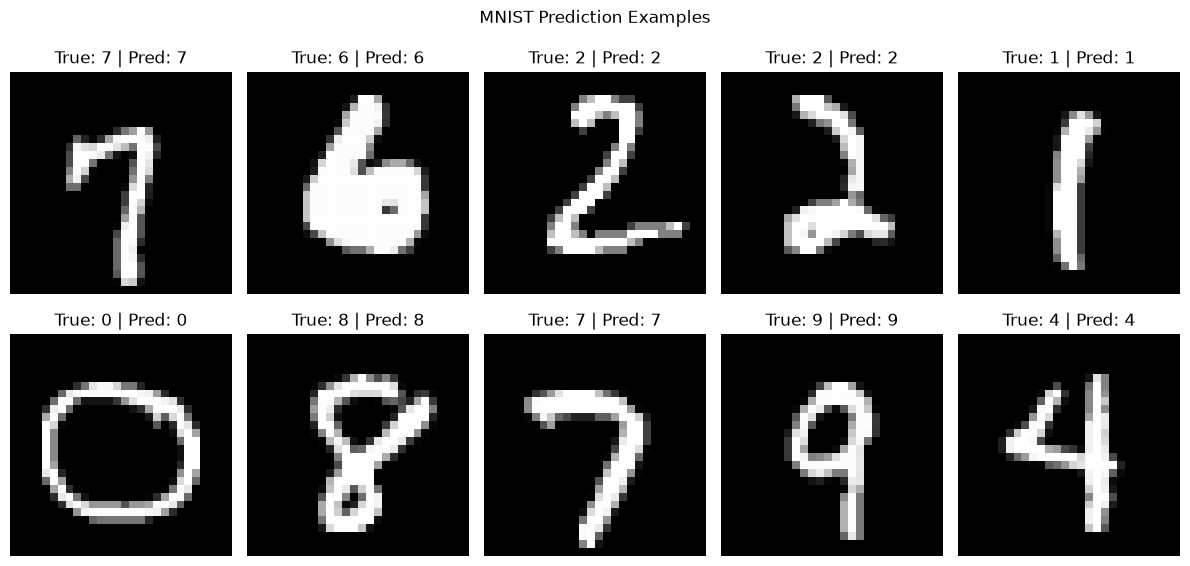

In [8]:
import numpy as np

# 随机选择 10 张测试图片
rng = np.random.default_rng(42)
indices = rng.choice(len(test_dataset), size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for ax, idx in zip(axes.flat, indices):
    image, true_label = test_dataset[int(idx)]

    # 增加 Batch 维度并移动到 GPU
    input_image = image.unsqueeze(0).to(device)

    with torch.no_grad():
        output = best_model(input_image)
        predicted_label = output.argmax(dim=1).item()

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"True: {true_label} | Pred: {predicted_label}")
    ax.axis("off")

plt.suptitle("MNIST Prediction Examples")
plt.tight_layout()

plt.savefig(
    "results/prediction_examples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
# 收集模型分类错误的样本
error_images = []
error_labels = []
error_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        # 找出预测错误的位置
        error_mask = predictions != labels

        error_images.extend(images[error_mask].cpu())
        error_labels.extend(labels[error_mask].cpu().tolist())
        error_predictions.extend(predictions[error_mask].cpu().tolist())

print("Total incorrect predictions:", len(error_images))

Total incorrect predictions: 139


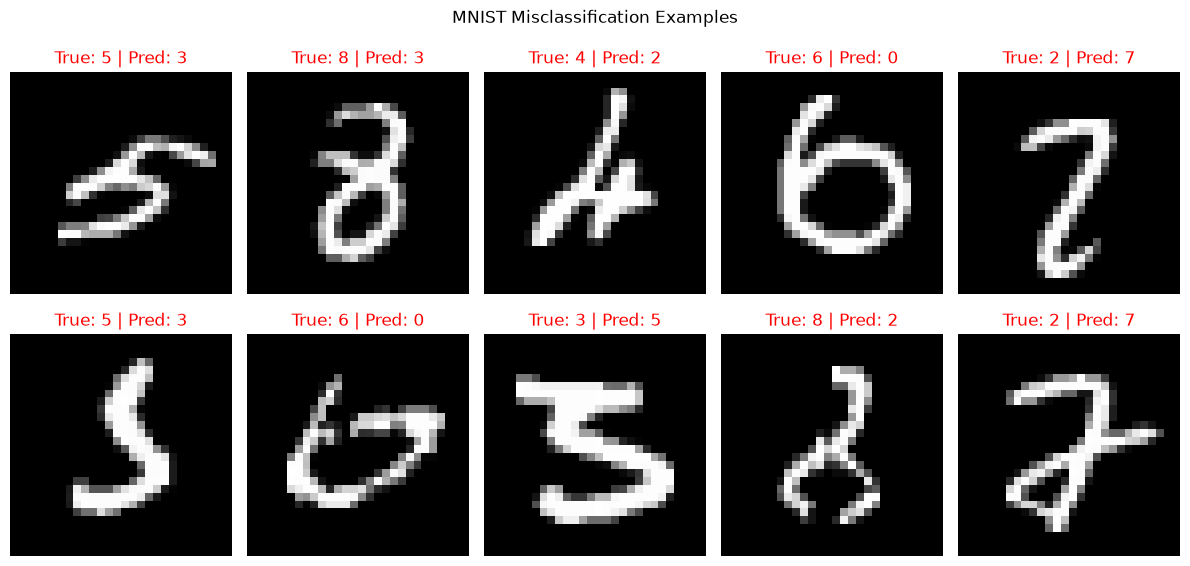

In [10]:
# 展示 10 个错误分类案例
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image = error_images[i]
    true_label = error_labels[i]
    predicted_label = error_predictions[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(
        f"True: {true_label} | Pred: {predicted_label}",
        color="red"
    )
    ax.axis("off")

plt.suptitle("MNIST Misclassification Examples")
plt.tight_layout()

plt.savefig(
    "results/error_cases.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()